In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

In [7]:
df = pd.read_csv('https://raw.githubusercontent.com/gscdit/Breast-Cancer-Detection/''refs/heads/master/data.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [8]:

print(df.shape)
print(len(df.columns))


df.drop(columns=['id', 'Unnamed: 32'], inplace=True)



(569, 33)
33


In [10]:
X = df.iloc[:, 1:].values   
y = df.iloc[:, 0].values 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test) 

In [12]:
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test  = encoder.transform(y_test)

In [14]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test,  dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_test_tensor  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)

print("X_train:", X_train_tensor.shape)
print("X_test: ", X_test_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("y_test: ", y_test_tensor.shape)

X_train: torch.Size([455, 30])
X_test:  torch.Size([114, 30])
y_train: torch.Size([455, 1])
y_test:  torch.Size([114, 1])


In [15]:
class BreastCancerNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(num_features, 16),
            nn.ReLU(),
            nn.Dropout(0.2),               # ওভারফিটিং কমায়
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid()                   # বাইনারি আউটপুট
        )

    def forward(self, x):
        return self.network(x)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print( device)

num_features = X_train_tensor.shape[1]
model = BreastCancerNN(num_features).to(device)

X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)
X_test_tensor  = X_test_tensor.to(device)
y_test_tensor  = y_test_tensor.to(device)

print(model)

cuda
BreastCancerNN(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Linear(in_features=8, out_features=1, bias=True)
    (6): Sigmoid()
  )
)


In [16]:
learning_rate = 0.1
epochs = 25

In [17]:
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [18]:
loss_history = []

print("\n==========Traning==========")
for epoch in range(epochs):
    model.train()                          # ট্রেইনিং মোড

    # ১. ফরওয়ার্ড
    y_pred = model(X_train_tensor)

    # ২. লস
    loss = criterion(y_pred, y_train_tensor)

    # ৩. গ্রেডিয়েন্ট রিসেট
    optimizer.zero_grad()

    # ৪. ব্যাকপ্রোপাগেশন
    loss.backward()

    # ৫. প্যারামিটার আপডেট
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:2d}/{epochs}]  Loss: {loss.item():.4f}")


==========Traning==========
Epoch [ 1/25]  Loss: 0.7010
Epoch [ 5/25]  Loss: 0.6692
Epoch [10/25]  Loss: 0.6340
Epoch [15/25]  Loss: 0.6007
Epoch [20/25]  Loss: 0.5588
Epoch [25/25]  Loss: 0.5073


In [19]:
model.eval()                               # ইভ্যালুয়েশন মোড
with torch.no_grad():                      # গ্রেডিয়েন্ট ট্র্যাকিং বন্ধ
    y_pred_prob = model(X_test_tensor)     # প্রোবাবিলিটি
    y_pred = (y_pred_prob > 0.5).float()   # ০.৫ থ্রেশহোল্ড

# CPU-তে নিয়ে NumPy-তে কনভার্ট
y_pred_np = y_pred.cpu().numpy().flatten()
y_true_np = y_test_tensor.cpu().numpy().flatten()

In [20]:
acc  = accuracy_score(y_true_np, y_pred_np)
prec = precision_score(y_true_np, y_pred_np)
rec  = recall_score(y_true_np, y_pred_np)
f1   = f1_score(y_true_np, y_pred_np)

print("\n========== test meatrix ==========")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true_np, y_pred_np))

print("\nClassification Report:")
print(classification_report(y_true_np, y_pred_np,target_names=["Benign (0)", "Malignant (1)"]))


========== test meatrix ==========
Accuracy : 0.9035
Precision: 0.9697
Recall   : 0.7619
F1 Score : 0.8533

Confusion Matrix:
[[71  1]
 [10 32]]

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.88      0.99      0.93        72
Malignant (1)       0.97      0.76      0.85        42

     accuracy                           0.90       114
    macro avg       0.92      0.87      0.89       114
 weighted avg       0.91      0.90      0.90       114



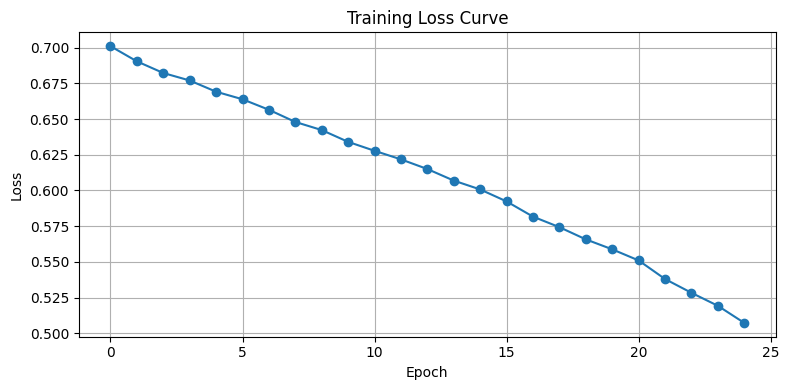

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history, marker='o')
plt.title("Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_curve.png")
plt.show()